# 第090讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Working directory:', pathlib.Path.cwd())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Working directory: /workspace/scratch/1577d0a62398/tutorials-20261019/machine-learning/units/090


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "integrity": {
    "valid_input_finite": true,
    "labels_in_range": true,
    "correct_pairing_check": true,
    "wrong_pairing_check": false,
    "gradient_without_step": 0.6222883462905884,
    "parameter_change_without_step": 0.0
  },
  "summary": {
    "clean": {
      "train_loss": [
        1.6490520238221507e-06,
        7.947274411890248e-07,
        1.4503748388960958e-06
      ],
      "val_acc": [
        0.7578125,
        0.73046875,
        0.75
      ]
    },
    "no_step": {
      "train_loss": [
        0.6830920577049255,
        0.7131798267364502,
        0.7538455128669739
      ],
      "val_acc": [
        0.45703125,
        0.42578125,
        0.4609375
      ]
    },
    "misaligned_order": {
      "train_loss": [
        0.6892545223236084,
        0.6888034343719482,
        0.682605504989624
      ],
      "val_acc": [
        0.51171875,
        0.51171875,
        0.5
      ]
    },
    "shuffled_labels": {
      "train_loss": [
        1.9480195987

In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+result.stderr)

test_group_totals (test_experiment.Tests.test_group_totals) ... ok
test_integrity (test_experiment.Tests.test_integrity) ... ok
test_no_step (test_experiment.Tests.test_no_step) ... ok
test_tiny_fit_and_random_memory (test_experiment.Tests.test_tiny_fit_and_random_memory) ... ok

----------------------------------------------------------------------
Ran 4 tests in 2.113s

OK



In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['environment', 'protocol', 'integrity', 'runs']


01_fault_curves.png
02_all_seeds.png
03_error_groups.png


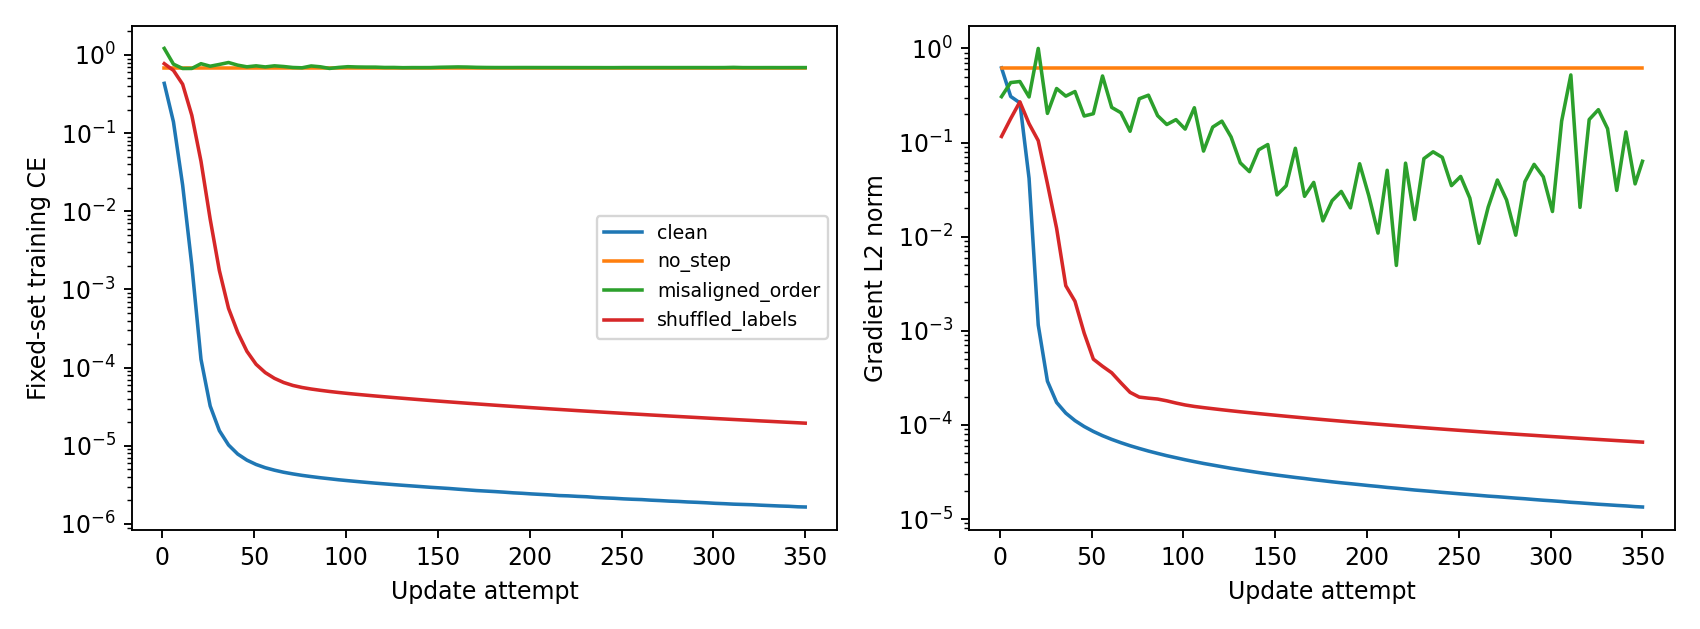

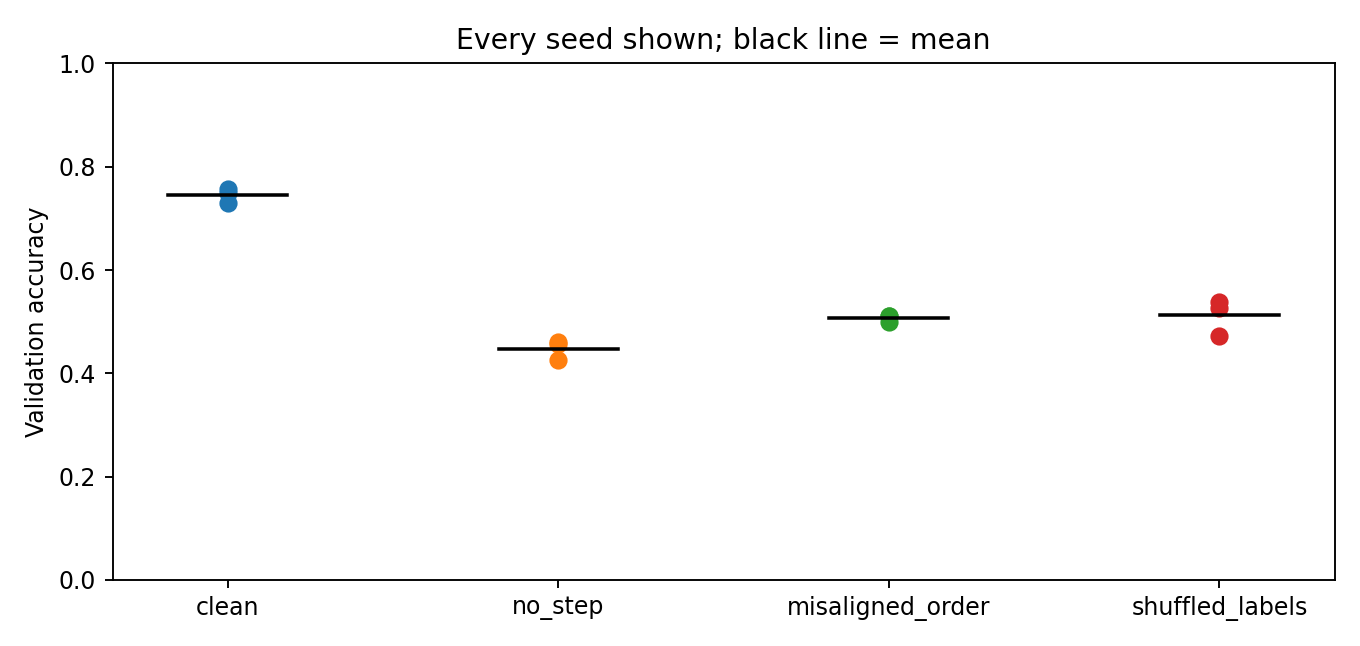

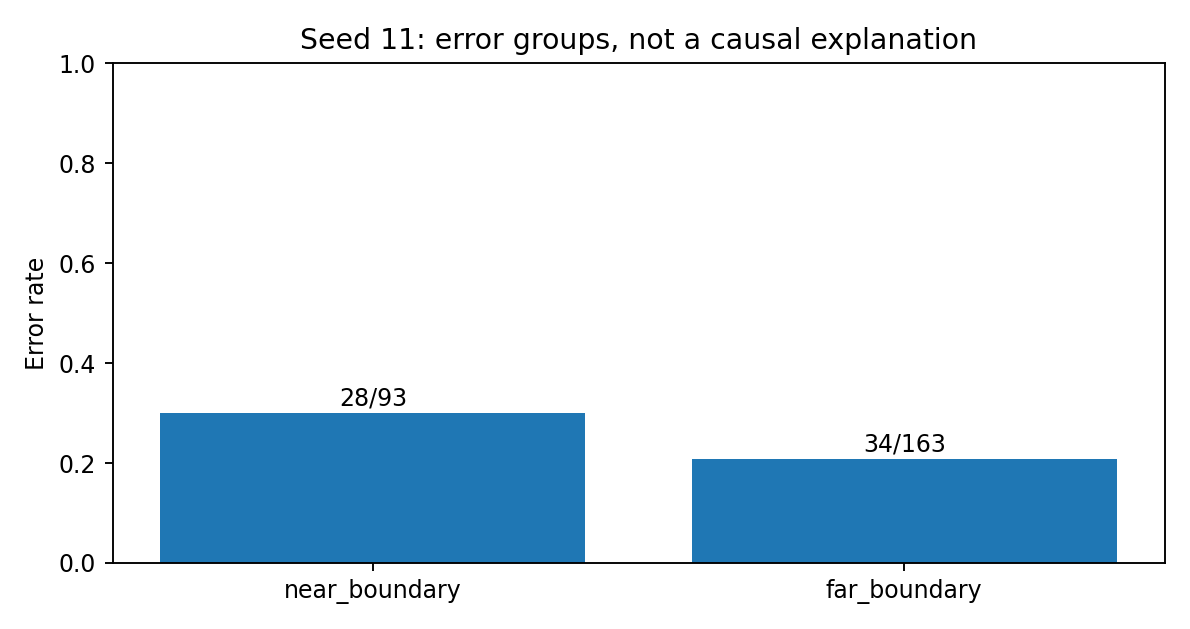

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。